In [15]:
# https://docs.pytorch.org/tutorials/beginner/nn_tutorial.html

In [16]:
import numpy as np
from matplotlib import pyplot as plt
import torch
from torch import optim

In [17]:
# params
alpha = 0.05 # day-1 
gamma = -6.0/1e3 # deg.m-1
dm = 1800. # m
beta_ref = 0.2/1e3 # m-1
zmin = 2000
zmax = 3500

In [18]:
z0 = zmin
zi_array = np.linspace(zmin,zmax)
t = np.arange(0,365) # day of water year

In [19]:
def massbal(previous_swe_array,T0,P0,beta):
    """
    heaviside : relu?
    nn.Linear
    """
    dz_array = zi_array - z0
    T_array = T0 + gamma * dz_array
    d_array = np.maximum(dz_array, dm)
    P_array = P0 * (1 + beta * d_array) / (1 - beta * d_array)
    Acc_array = P_array * (0.5 + 0.5 * np.tanh(-10 * T_array))
    Abl_array = np.minimum(previous_swe_array, alpha * T_array * np.heaviside(T_array,0))
    swe_array = previous_swe_array + Acc_array - Abl_array
    return swe_array

In [20]:
T0_series = 10 + 10 * np.cos(2*np.pi*t/365)

In [21]:
P0_series = 0.01 + 0.01 * np.cos(2*np.pi*t/365 + np.pi)
rng = np.random.default_rng(42)
ix = rng.choice(len(P0_series),int(np.round(0.8*len(t))),replace=False)
P0_series[ix] = 0

In [22]:
swe_array_previous = np.zeros_like(zi_array)
swe_array_series = np.zeros((*zi_array.shape,len(t)))
for it in range(len(t)) :
    it = t[it]
    T0 = T0_series[it]
    P0 = P0_series[it]
    swe_array_current = massbal(swe_array_previous,T0,P0,beta_ref)
    swe_array_series[:,it] = swe_array_current
    swe_array_previous = swe_array_current
mean_swe_series_target = swe_array_series.mean(axis=0)

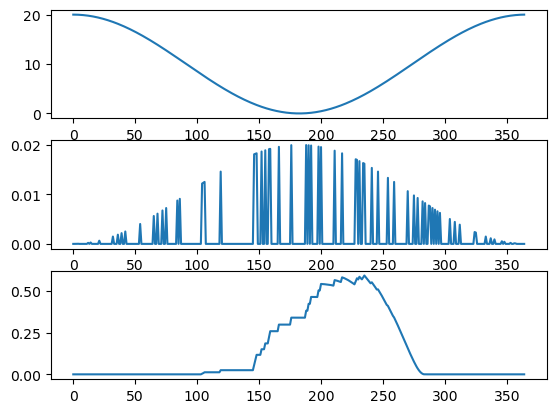

In [23]:
fig, axs = plt.subplots(3,1)
axs[0].plot(t, T0_series)
axs[1].plot(t, P0_series)
axs[2].plot(t, mean_swe_series_target);

In [24]:
def massbaltorch(previous_swe_array,T0,P0,beta):
    dz_array = torch.tensor(zi_array - z0,requires_grad=False)
    T_array = T0 + torch.tensor(gamma,requires_grad=False) * dz_array
    d_array = torch.maximum(dz_array, torch.tensor(dm,requires_grad=False))
    P_array = P0 * (1 + beta * d_array) / (1 - beta * d_array)
    Acc_array = P_array * (0.5 + 0.5 * torch.tanh(-10 * T_array))
    Abl_array = torch.minimum(
        previous_swe_array, alpha * T_array * torch.relu(T_array))
    swe_array = previous_swe_array + Acc_array - Abl_array
    return swe_array

In [25]:
# model which maps precip correction factor to swe time series
def model1(param):
    beta = param * beta_ref
    swe_array_previous = torch.tensor(np.zeros_like(zi_array))
    swe_array_series = torch.tensor(np.zeros((*zi_array.shape,len(t))))
    for it in range(len(t)) :
        it = t[it]
        T0 = torch.tensor(T0_series[it])
        P0 = torch.tensor(P0_series[it])
        swe_array_current = massbaltorch(swe_array_previous,T0,P0,beta)
        swe_array_series[:,it] = swe_array_current
        swe_array_previous = swe_array_current
    mean_swe_series = swe_array_series.mean(axis=0)
    return mean_swe_series

In [26]:
def loss_func(input, target):
    """
    RMSE
    """
    return torch.sqrt(torch.mean((input - target)*(input - target)))


In [27]:
ref = torch.tensor(mean_swe_series_target)

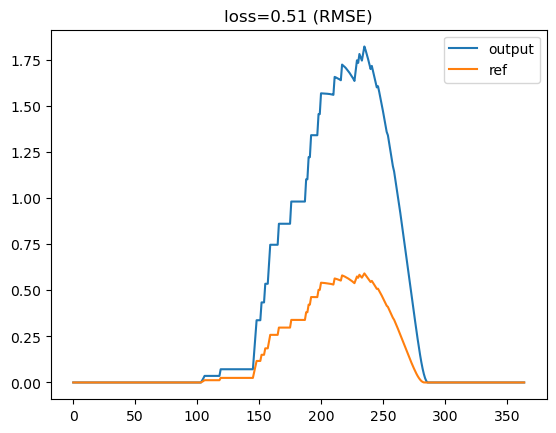

In [31]:
param=torch.tensor(2., requires_grad=False)
preds = model1(param)  # predictions
plt.plot(t,preds.detach(),label='output')
plt.plot(t,mean_swe_series_target,label='ref')
plt.legend()
plt.title(f'loss={loss_func(preds, ref):.2f} (RMSE)');

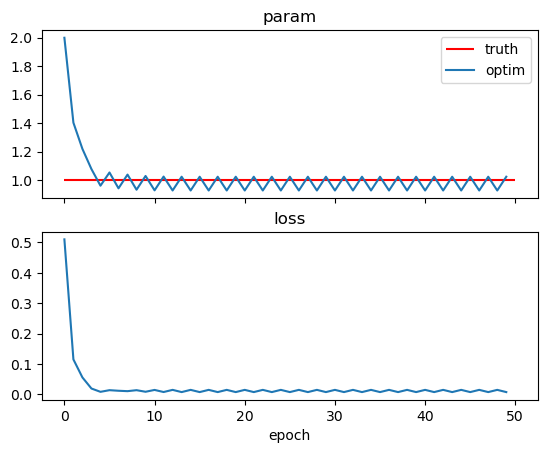

final param=0.93, final loss=0.01 (RMSE)


tensor(0.5103, dtype=torch.float64, grad_fn=<SqrtBackward0>)

In [50]:
def fit(model=model1, init_factor=2., lr=0.5, epochs=50):
    param=torch.tensor(init_factor, requires_grad=True)
    out = np.zeros((2,epochs))
    for epoch in range(epochs):
        pred = model(param)
        loss = loss_func(pred, ref)
        out[:,epoch] = param.detach(),loss.detach()
        loss.backward()
        with torch.no_grad():
            param -= param.grad * lr
            param.grad.zero_()
    fig,axs = plt.subplots(2,1, sharex=True)
    axs[0].hlines(1, xmin=0, xmax=epochs, label='truth', color='r')
    axs[0].plot(out[0,:],label='optim')
    axs[0].legend()
    axs[0].set_title('param')
    axs[1].plot(out[1,:], label='loss')
    axs[1].set_title('loss')
    axs[1].set_xlabel('epoch')
    plt.show()  
    print(f'final param={param.detach():.2f}, final loss={loss.detach():.2f} (RMSE)')
fit()

[Parameter containing:
tensor(2., requires_grad=True)]


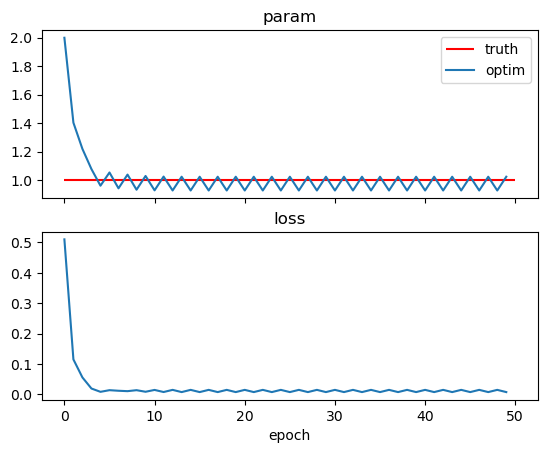

final param=0.93, final loss=0.01 (RMSE)


In [33]:
from torch import nn

class MyModule(nn.Module):
    def __init__(self):
        super().__init__()
        self.selfmodel = model1
        self.par = torch.nn.parameter.Parameter(data=param, requires_grad=True)
#        self.params = nn.ParameterList([nn.Parameter(torch.tensor(2., requires_grad=True)) for i in range(2)])

    def forward(self, par):
        return self.selfmodel(par)

model2 = MyModule()
print(list(MyModule.parameters(model2)))
fit(model2)


In [ ]:
from torch import optim
def get_model():
    model = MyModule()
    return model, optim.SGD(model.parameters(), lr=lr, momentum=0.9)

In [69]:
model, opt = get_model()
print(list(model.parameters()))

[Parameter containing:
tensor(0.9284, requires_grad=True)]


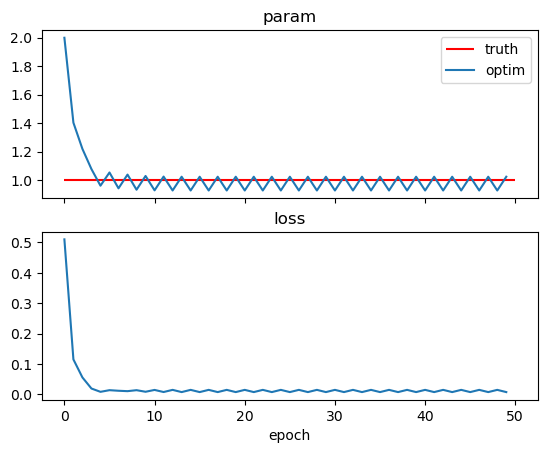

final param=0.93, final loss=0.01 (RMSE)


In [70]:
fit(model)

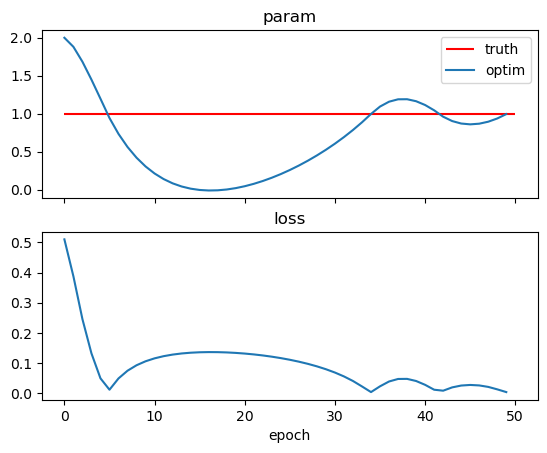

final param=0.93, final loss=0.00 (RMSE)


In [72]:

init_factor=2.
lr=0.1
epochs=50
model, opt = get_model()
model.par.data = torch.tensor(init_factor, requires_grad=True)

out = np.zeros((2,epochs))
for epoch in range(epochs):
    opt.zero_grad()
    pred = model(model.par)
    loss = loss_func(pred, ref)
    out[:,epoch] = model.par.detach(),loss.detach()
    loss.backward()
    opt.step()


fig,axs = plt.subplots(2,1, sharex=True)
axs[0].hlines(1, xmin=0, xmax=epochs, label='truth', color='r')
axs[0].plot(out[0,:],label='optim')
axs[0].legend()
axs[0].set_title('param')
axs[1].plot(out[1,:], label='loss')
axs[1].set_title('loss')
axs[1].set_xlabel('epoch')
plt.show()  
print(f'final param={param.detach():.2f}, final loss={loss.detach():.2f} (RMSE)')



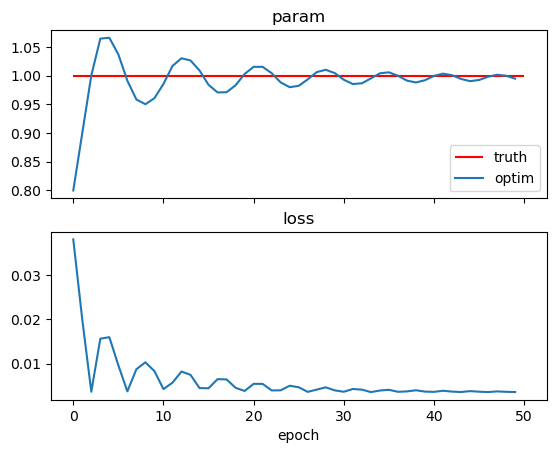

final param=0.93, final loss=0.00 (RMSE)


In [98]:
from torch import optim
def get_model():
    model = MyModule()
    return model, optim.Adam(model.parameters(), lr=lr)

init_factor=.8
lr=0.1
epochs=50
model, opt = get_model()
model.par.data = torch.tensor(init_factor, requires_grad=True)

out = np.zeros((2,epochs))
for epoch in range(epochs):
    opt.zero_grad()
    pred = model(model.par)
    loss = loss_func(pred, ref)
    out[:,epoch] = model.par.detach(),loss.detach()
    loss.backward()
    opt.step()


fig,axs = plt.subplots(2,1, sharex=True)
axs[0].hlines(1, xmin=0, xmax=epochs, label='truth', color='r')
axs[0].plot(out[0,:],label='optim')
axs[0].legend()
axs[0].set_title('param')
axs[1].plot(out[1,:], label='loss')
axs[1].set_title('loss')
axs[1].set_xlabel('epoch')
plt.show()  
print(f'final param={param.detach():.2f}, final loss={loss.detach():.2f} (RMSE)')

